# Olist E-Commerce Analysis — What Makes Customers Happy or Angry?

Hi, I'm **Vivek Saini**, a Data Analyst from Meerut, India. This is my third
portfolio project. My first two projects used data I created myself. This
time I wanted the real thing, so I worked on **real data from Olist**, a
real marketplace in Brazil.

The data has **99,441 orders** from 2016 to 2018 —
what people bought, how they paid, when the parcel reached them, and the
review score they gave after delivery.

I asked one main question in different ways:

> **What makes a customer happy or angry on a marketplace?**

My guess before starting: delivery. If a parcel comes late, the customer
gets angry, and the review shows it. This notebook tests that guess, plus
a few more questions about categories, payments, repeat buyers and
delivery charges.

**Data source and credit:** Olist — published openly on GitHub
(github.com/olist/work-at-olist-data) under the **CC BY-NC-SA 4.0**
licence. The data is real and belongs to Olist. Only the code in this
project is mine.

**Tools:** Python, pandas, SQL (SQLite), matplotlib, Jupyter.

## Step 1 — Get the data

The `download_data.py` script in this project pulls the 8 tables straight
from Olist's GitHub page. No copy-paste, no fake rows. Let me load them
and see what we have.

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
from IPython.display import Image

pd.set_option("display.max_columns", 20)

files = {
    "orders": "olist_orders_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "translation": "product_category_name_translation.csv",
}
tables = {name: pd.read_csv("data/" + f) for name, f in files.items()}
for name, t in tables.items():
    print(f"{name:12s} {len(t):>8,} rows   {t.shape[1]} columns")

orders         99,441 rows   8 columns
items         112,650 rows   7 columns
payments      103,886 rows   5 columns
reviews        99,224 rows   7 columns
customers      99,441 rows   5 columns
products       32,951 rows   9 columns
sellers         3,095 rows   4 columns
translation        71 rows   2 columns


## Step 2 — Meet the tables

The tables connect like this:

- **orders** — one row per order: status, purchase time, promised delivery date, real delivery date
- **items** — one row per product in an order: price and delivery charge (freight)
- **payments** — how each order was paid: card, boleto (a Brazilian bank slip), voucher…
- **reviews** — the 1 to 5 star score the customer gave
- **customers** — city and state of the buyer
- **products** — product category (in Portuguese!)
- **sellers** — who sold the item
- **translation** — Portuguese category names changed to English

Here is the orders table, and how many orders sit in each status:

In [2]:
tables["orders"].head(3)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


In [3]:
tables["orders"]["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Most orders are **delivered** (96,478). A few are
cancelled or stuck on the way. For delivery questions, only delivered
orders make sense — a cancelled order never reached anyone.

## Step 3 — Clean and join

Real data is never ready to use. The problems I had to fix:

1. **Cancelled and "unavailable" orders** — kept for sales totals, removed
   from the delivery analysis.
2. **Missing dates** — some delivered orders have no delivery date, so no
   delay can be worked out for them.
3. **Two reviews for one order** — a few orders were reviewed twice. I
   kept the latest review.
4. **Portuguese category names** — changed to English with the
   translation table.
5. **Orders with many items** — for "the category of an order" I used the
   category of its most costly item. A simple rule, and I state it openly.
6. **{F['table_rows']['orders'] - F['joined_rows']:,} orders had no items at all** — no
   products, no price. They cannot be studied, so the joined table drops
   them.

The full cleaning code lives in `analysis.py`. Here I call it and work
with the joined table it builds — one row per order:

In [4]:
from analysis import build_joined

df, counts, items_full, reviews_raw, payments_raw = build_joined()
print("joined table:", df.shape)
df[["order_id", "order_status", "main_category", "items_price",
    "freight", "main_payment_type", "review_score",
    "customer_state", "delay_days"]].head()

joined table: (98666, 24)


,order_id,order_status,main_category,items_price,freight,main_payment_type,review_score,customer_state,delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,housewares,29.99,8.72,voucher,4.0,SP,-7.107488
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,perfumery,118.70,22.76,boleto,4.0,BA,-5.355729
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,auto,159.90,19.22,credit_card,5.0,GO,-17.245498
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,pet_shop,45.00,27.20,credit_card,5.0,RN,-12.980069
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,stationery,19.90,8.72,credit_card,5.0,SP,-9.238171


In [5]:
# a look at the cleaning problems, in numbers
delivered = df[df["order_status"] == "delivered"]
print("review rows in raw table      :", f"{len(reviews_raw):,}")
print("orders with a review (joined) :", f"{df['review_score'].notna().sum():,}")
print("delivered orders              :", f"{len(delivered):,}")
print("...but no delivery date       :", f"{delivered['order_delivered_customer_date'].isna().sum():,}")
print("cancelled + unavailable orders:", f"{df['order_status'].isin(['canceled', 'unavailable']).sum():,}")

review rows in raw table      : 99,224
orders with a review (joined) : 97,917
delivered orders              : 96,478
...but no delivery date       : 8
cancelled + unavailable orders: 467


In [6]:
# Portuguese -> English, one small example
tr = tables["translation"].copy()
tr.columns = [c.strip().lstrip("\ufeff") for c in tr.columns]
tr.head(5)

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


## Question 1 — Does late delivery hurt the review score?

Every order has a **promised** delivery date and a **real** delivery date.
I worked out the gap in days and put each delivered order into a group:
early or on time, 1–3 days late, 4–7 days late, or 8+ days late.

Only **8.0%** of delivered orders were late at all.
The average delivery took **12.6 days** — Brazil is a
big country. So the real question is not "are they slow?" but "what
happens when they break the promise?"

In [7]:
d = df[df["order_status"] == "delivered"].dropna(subset=["delay_days", "review_score"])
order = ["Early or on time", "1-3 days late", "4-7 days late", "8+ days late"]
d = d.assign(delay_bucket=pd.Categorical(d["delay_bucket"], categories=order, ordered=True))
table = d.groupby("delay_bucket", observed=True).agg(
    orders=("order_id", "count"),
    avg_review=("review_score", "mean"),
    five_star_pct=("review_score", lambda s: (s == 5).mean() * 100),
    one_star_pct=("review_score", lambda s: (s == 1).mean() * 100),
).round(2)
table

,orders,avg_review,five_star_pct,one_star_pct
delay_bucket,,,,
Early or on time,88163,4.29,62.43,6.59
1-3 days late,2636,3.77,43.21,13.77
4-7 days late,1773,2.32,18.16,53.02
8+ days late,3252,1.73,7.47,68.82


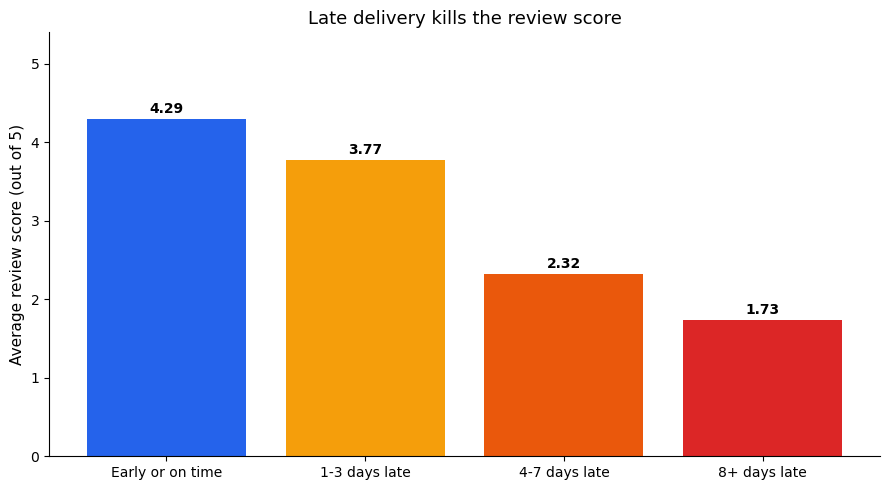

In [8]:
%matplotlib inline
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#2563eb", "#f59e0b", "#ea580c", "#dc2626"]
bars = ax.bar(table.index.astype(str), table["avg_review"], color=colors)
ax.set_ylim(0, 5.4)
ax.set_ylabel("Average review score (out of 5)")
ax.set_title("Late delivery kills the review score")
for bar, v in zip(bars, table["avg_review"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.08, f"{v:.2f}",
            ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

This is the clearest result in the whole project:

| | On time | Late (any) | 8+ days late |
|---|---|---|---|
| Average review | **4.29** | **2.57** | **1.73** |
| 5-star reviews | 62.4% | 22.2% | 7.5% |
| 1-star reviews | 6.6% | 46.2% | 68.8% |

A small delay of 1–3 days costs a little (average 3.77).
But past a week, the customer is gone — **68.8% of
very late orders got the worst score of 1 star.**

So the promise matters more than the speed. Olist is slow but mostly
honest: 92.0% of orders reached on or before the
promised date, and those customers stayed happy.

## Question 2 — Which categories earn the most, and which make customers happy?

Total product sales in this data: **R$ 13.49 million**.
The top earner is **health beauty** with R$ 1,256,377.

But money and happiness are not the same thing, as the review table
shows. (I only ranked categories with 300+ reviewed orders, so a tiny
category with 5 lucky reviews cannot top the list.)

In [9]:
valid = df[~df["order_status"].isin(["canceled", "unavailable"])]
revenue_by_cat = (valid.groupby("main_category")["items_price"]
                  .sum().sort_values(ascending=False).head(5))
revenue_by_cat.rename("revenue_R$").round(2)

main_category
health_beauty            1256376.51
watches_gifts            1199160.41
bed_bath_table           1037531.86
sports_leisure            979414.26
computers_accessories     904519.02
Name: revenue_R$, dtype: float64

In [10]:
cat_review = (df[df["order_status"] == "delivered"]
              .dropna(subset=["review_score"])
              .groupby("main_category")["review_score"]
              .agg(["mean", "count"]))
cat_review = cat_review[cat_review["count"] >= 300].sort_values("mean")
print("WORST 5 by review:")
display(cat_review.head(5).round(2))
print("BEST 5 by review:")
display(cat_review.tail(5).iloc[::-1].round(2))

WORST 5 by review:


,mean,count
main_category,,
office_furniture,3.65,1241
audio,3.85,341
home_confort,3.92,362
bed_bath_table,4.01,9095
home_construction,4.03,470


BEST 5 by review:


,mean,count
main_category,,
books_general_interest,4.54,489
luggage_accessories,4.37,1009
food,4.34,432
stationery,4.31,2231
pet_shop,4.28,1673


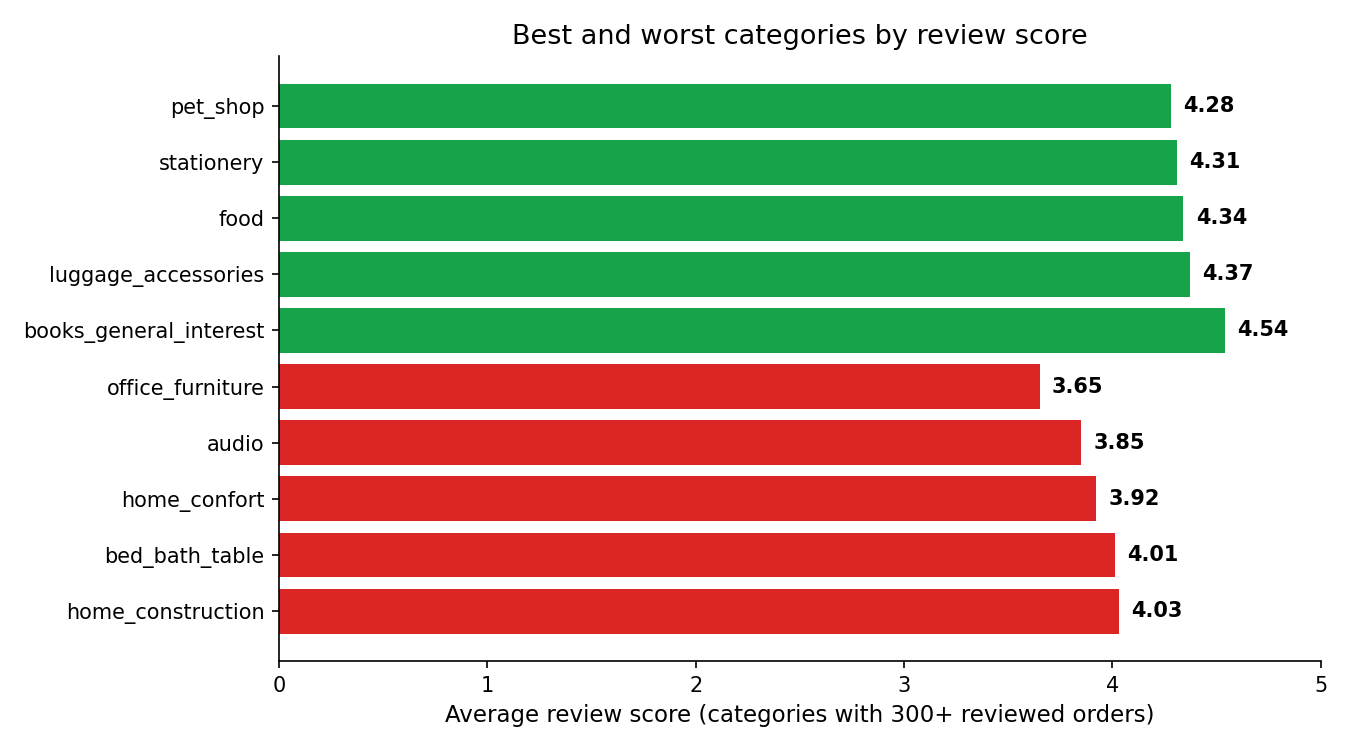

In [11]:
Image("charts/review_by_category.png")

Two things stood out for me:

- **office furniture** is the worst-rated category at **3.65**
  stars (1,241 orders). Big furniture is heavy, easy to
  damage and slow to move — the next section shows its delivery charge is
  also one of the highest.
- **bed bath table** is the third-biggest earner (R$ 1,037,532)
  but scores only **4.01** — below average. A small
  quality fix in a category this big moves a lot of money.
- Books make people happiest: **books general interest** tops the list at
  **4.54** stars.

## Question 3 — How do customers pay?

Brazil pays in a way that surprised me. **Credit card is king —
75.5% of orders.** And most card
buyers do not pay at once: they split the bill into monthly parts
(installments), which is normal in Brazil.

| Payment type | Share of orders | Average order value |
|---|---|---|
| Credit card | 75.5% | R$ 167 |
| Boleto (bank slip) | 19.9% | R$ 145 |
| Voucher | 3.1% | R$ 115 |
| Debit card | 1.5% | R$ 140 |

In [12]:
pay = valid.dropna(subset=["main_payment_type"])
pay = pay[pay["main_payment_type"] != "not_defined"]
pay_table = pay.groupby("main_payment_type").agg(
    orders=("order_id", "count"),
    share_pct=("order_id", lambda s: len(s) / len(pay) * 100),
    avg_order_value=("paid_value", "mean"),
    avg_installments=("installments", "mean"),
).round(1).sort_values("orders", ascending=False)
pay_table

,orders,share_pct,avg_order_value,avg_installments
main_payment_type,,,,
credit_card,74112,75.5,166.6,3.6
boleto,19535,19.9,144.7,1.0
voucher,3037,3.1,114.9,1.0
debit_card,1514,1.5,140.3,1.0


In [13]:
cc = pay[pay["main_payment_type"] == "credit_card"]
print(f"credit card orders                 : {len(cc):,}")
print(f"paid in installments (>1 part)     : {(cc['installments'] > 1).mean() * 100:.1f}%")
print(f"paid in 8 or more parts            : {(cc['installments'] >= 8).mean() * 100:.1f}%")
print(f"avg value, paid at once            : R$ {cc[cc['installments'] == 1]['paid_value'].mean():,.2f}")
print(f"avg value, paid in installments    : R$ {cc[cc['installments'] > 1]['paid_value'].mean():,.2f}")

credit card orders                 : 74,112
paid in installments (>1 part)     : 68.0%
paid in 8 or more parts            : 14.0%
avg value, paid at once            : R$ 100.82


avg value, paid in installments    : R$ 197.64


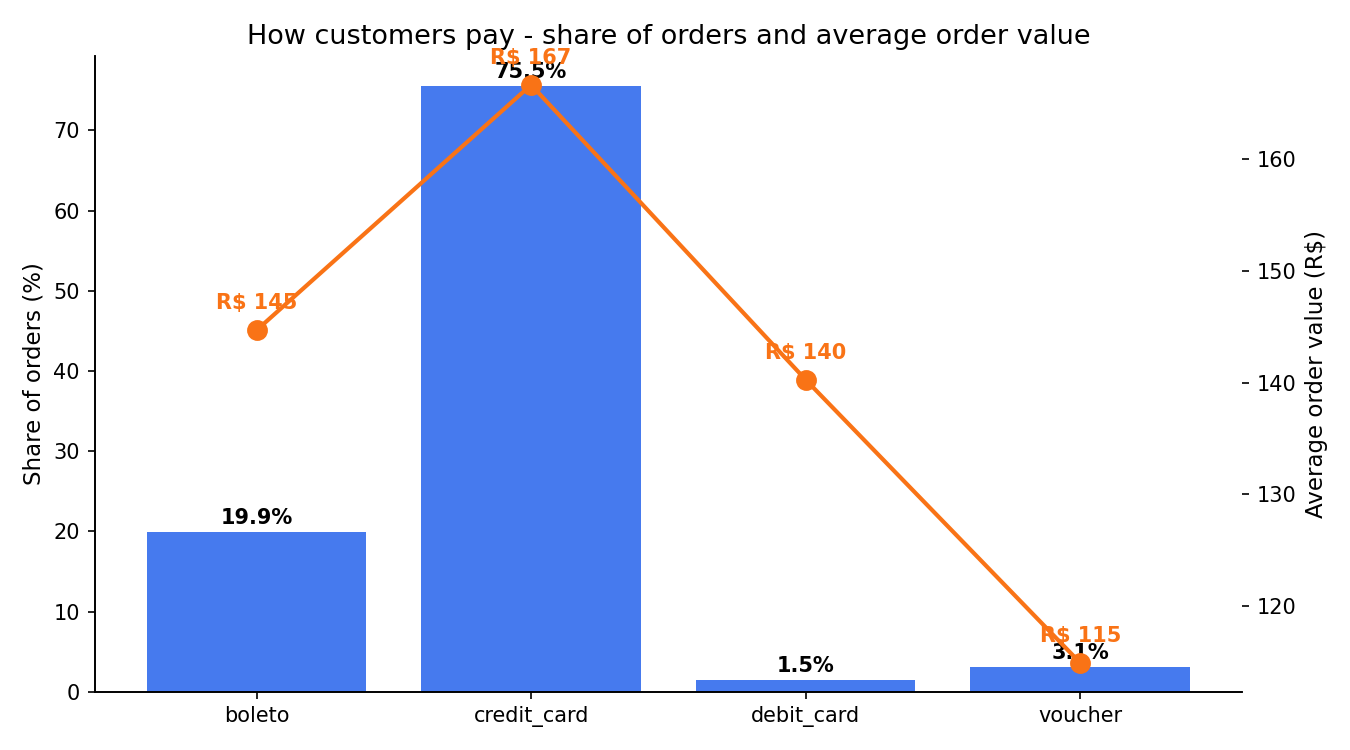

In [14]:
Image("charts/payment_types.png")

The lesson is simple and strong: **when people can pay slowly, they
buy bigger.** An order paid in parts is worth **R$ 198**
on average, against **R$ 101** for a
one-time card payment — almost double. And 14.0%
of card buyers split into 8 or more parts. Credit access is not a side
detail here; it is a sales tool.

## Question 4 — How did sales grow, and where do buyers live?

The marketplace grew fast. In **2017-01** it took
only **787 orders**. By
**2017-11** — the Black Friday month — it took
**7,421 orders** and R$ 1,003,862
in product sales. In 2018-08, the last full month,
it was still at 6,421 orders.

In [15]:
trend = (valid.groupby("purchase_month")
         .agg(orders=("order_id", "count"), revenue=("items_price", "sum")))
trend = trend.loc["2017-01":"2018-08"]
trend.head(3)

,orders,revenue
purchase_month,,
2017-01,787,120098.27
2017-02,1718,244959.35
2017-03,2617,368341.32


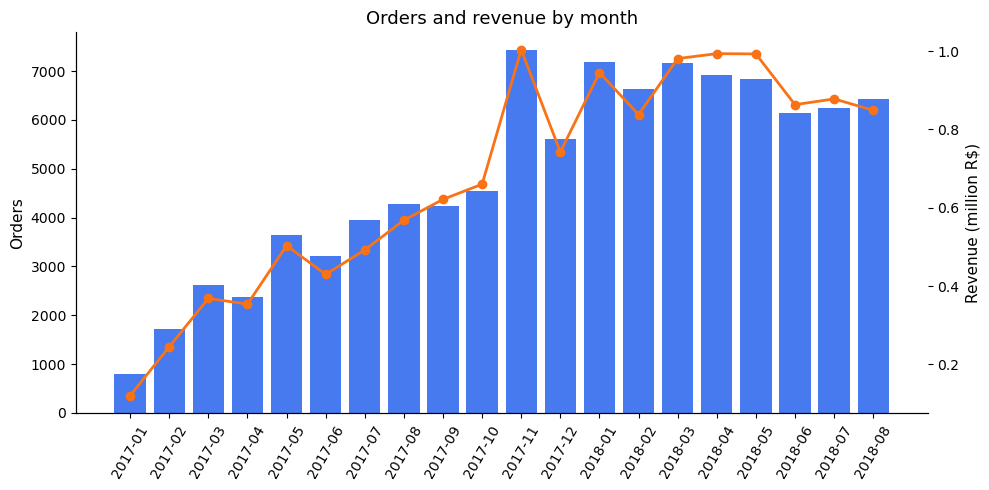

In [16]:
%matplotlib inline
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(trend.index, trend["orders"], color="#2563eb", alpha=0.85)
ax1.set_ylabel("Orders")
ax1.tick_params(axis="x", rotation=60)
ax2 = ax1.twinx()
ax2.plot(trend.index, trend["revenue"] / 1e6, color="#f97316", marker="o", linewidth=2)
ax2.set_ylabel("Revenue (million R$)")
ax1.set_title("Orders and revenue by month")
plt.tight_layout()
plt.show()

In [17]:
states = (valid.groupby("customer_state")
          .agg(orders=("order_id", "count"), revenue=("items_price", "sum"))
          .sort_values("revenue", ascending=False).head(10))
states["revenue"] = states["revenue"].round(2)
states

,orders,revenue
customer_state,,
SP,41125,5163867.22
RJ,12697,1811623.42
MG,11496,1573508.20
RS,5415,742559.78
PR,4982,676883.06
SC,3599,518578.28
BA,3344,507108.83
DF,2120,300886.45
GO,1998,287870.46


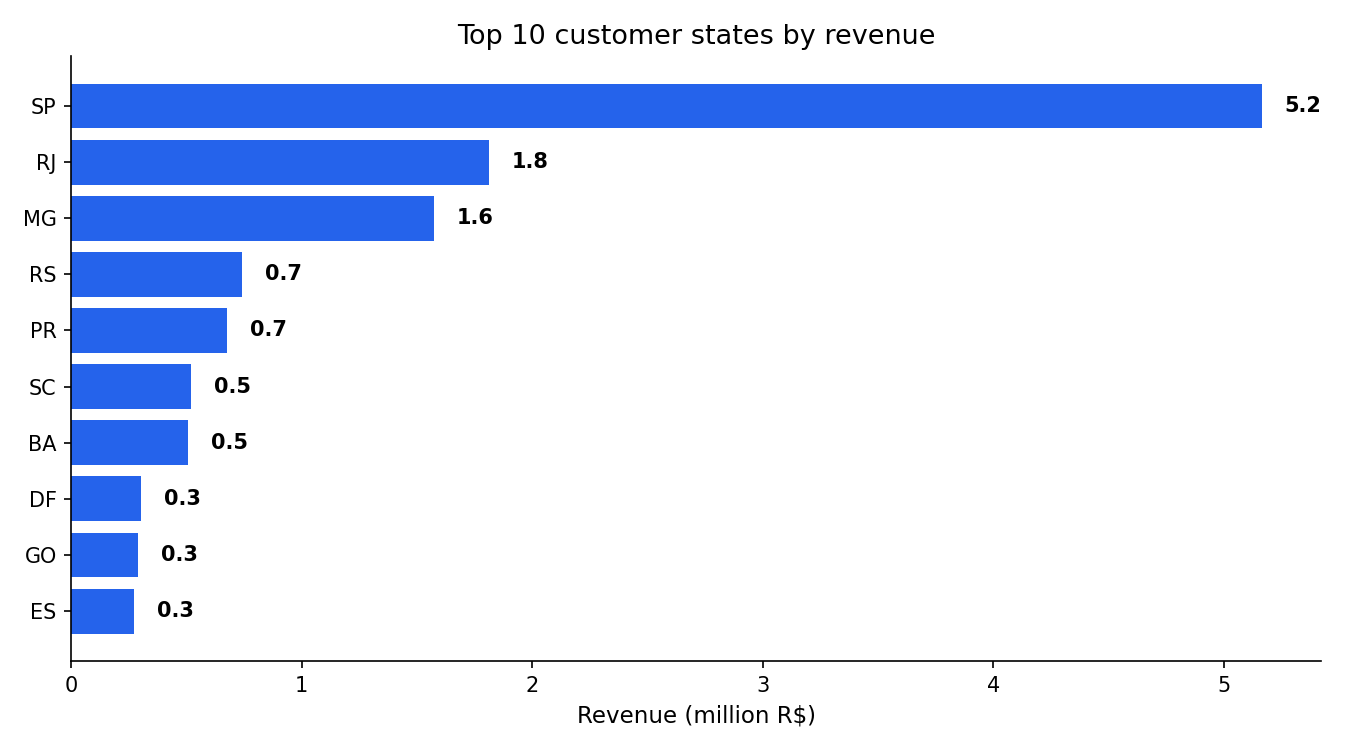

In [18]:
Image("charts/top_states.png")

One state runs the show: **SP (São Paulo)** brings
**38.3% of all revenue** with
41,125 orders. The next states, RJ and MG, are far
behind. Protecting delivery quality in SP matters more than anywhere
else — and the rest of the country is the growth space.

## Question 5 — Do customers come back?

This is the sad number of the project. Out of
**95,420 different customers**, only
**3.1% ever placed a second order.**
96.9% bought once and never returned. The most
loyal customer in the whole data placed 16 orders.

The marketplace is good at winning new customers. It is not good at
keeping them.

In [19]:
per_customer = df.groupby("customer_unique_id")["order_id"].count()
print(f"unique customers          : {len(per_customer):,}")
print(f"ordered exactly once      : {(per_customer == 1).mean() * 100:.1f}%")
print(f"ordered 2 or more times   : {(per_customer >= 2).mean() * 100:.1f}%")
print(f"most orders by one person : {per_customer.max()}")

unique customers          : 95,420
ordered exactly once      : 96.9%
ordered 2 or more times   : 3.1%
most orders by one person : 16


## Question 6 — How much of the basket goes to delivery?

Every order pays freight (delivery charge) on top of the product price.
Across the whole marketplace, freight adds up to
**16.6% of the product value**. But averages
hide the pain: per order, the average share is
**30.9%**, because small orders carry
heavy delivery charges. In **35.1% of
orders, the delivery charge is more than 30% of what the product itself
costs.**

In [20]:
fr = (valid.groupby("main_category")
      .agg(freight=("freight", "sum"), price=("items_price", "sum"),
           orders=("order_id", "count")))
fr = fr[fr["orders"] >= 1000]
fr["freight_share_pct"] = (fr["freight"] / fr["price"] * 100).round(1)
fr.sort_values("freight_share_pct", ascending=False)

,freight,price,orders,freight_share_pct
main_category,,,,
electronics,46438.85,157404.33,2529,29.5
office_furniture,68571.90,274550.94,1269,25.0
furniture_decor,171857.59,725253.28,6306,23.7
housewares,145931.20,626523.04,5784,23.3
telephony,70766.16,321917.89,4163,22.0
luggage_accessories,30408.21,140178.23,1024,21.7
fashion_bags_accessories,31304.79,151604.77,1848,20.6
garden_tools,97770.66,478555.48,3457,20.4
stationery,46527.05,229816.81,2279,20.2


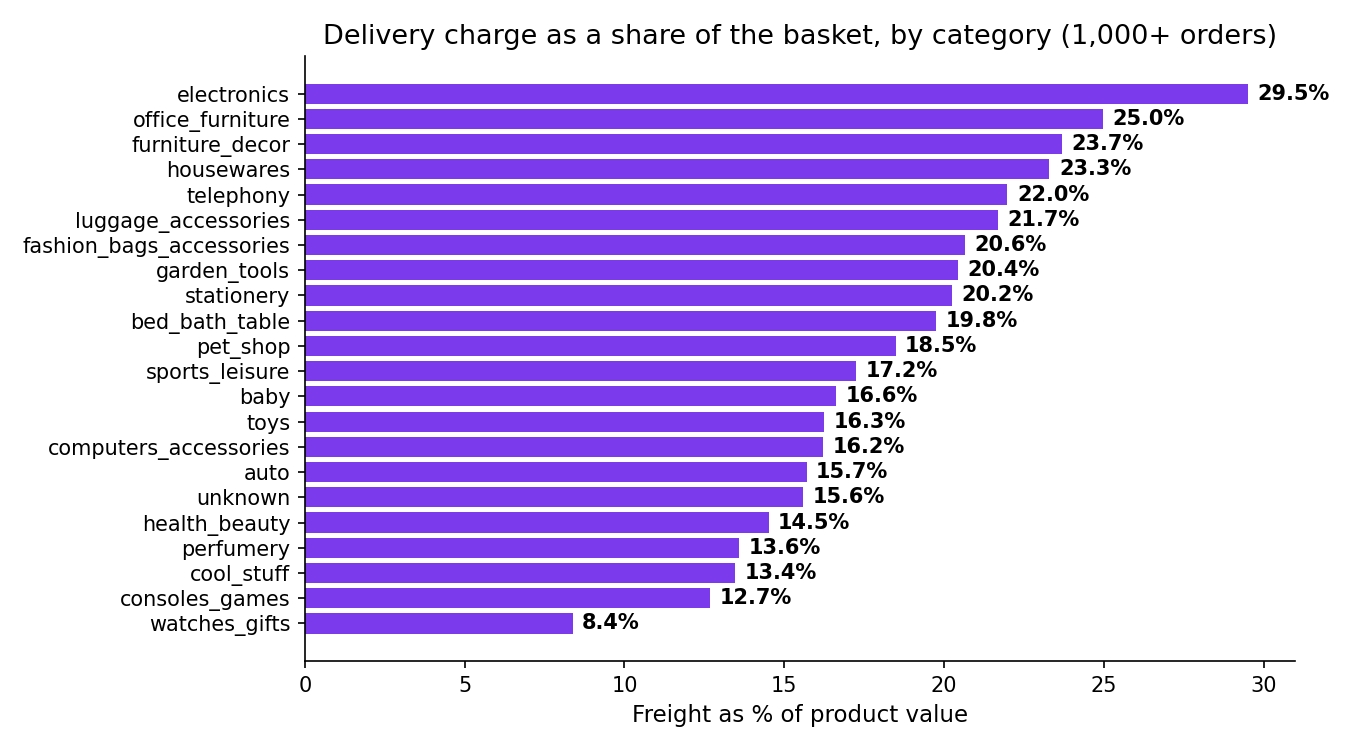

In [21]:
Image("charts/freight_share.png")

Heavy and costly-to-move things suffer most:
**electronics** buyers pay 29.5% extra in delivery,
and **furniture living room** 26.3%. Remember the worst-rated
category, office furniture? Its freight share is 25.0% — high
delivery cost and bad reviews in the same place. At the other end,
**watches gifts** adds only 8.4% — costly products carry
their delivery charge easily.

## The same questions in SQL

Charts are nice, but a data analyst must also speak SQL. `analysis.py`
built a small SQLite database (`data/olist.sqlite`) with the raw tables
plus my joined table. Here are the main questions again as SQL queries
with real joins.

In [22]:
con = sqlite3.connect("data/olist.sqlite")
# one index on the reviews table - the "latest review per order"
# query below is painfully slow without it (I timed it: 90+ seconds
# without the index, under 1 second with it)
con.execute("CREATE INDEX IF NOT EXISTS idx_reviews_order ON reviews(order_id)")
con.commit()
pd.read_sql('''
SELECT i.category,
       COUNT(DISTINCT i.order_id) AS orders,
       ROUND(SUM(i.price), 2)     AS revenue
FROM order_items i
JOIN orders o ON o.order_id = i.order_id
WHERE o.order_status NOT IN ('canceled', 'unavailable')
GROUP BY i.category
ORDER BY revenue DESC
LIMIT 5
''', con)

,category,orders,revenue
0,health_beauty,8800,1255695.13
1,watches_gifts,5604,1198185.21
2,bed_bath_table,9399,1035964.06
3,sports_leisure,7673,979740.92
4,computers_accessories,6654,904322.02


In [23]:
pd.read_sql('''
WITH latest AS (
    SELECT r.order_id, r.review_score
    FROM reviews r
    WHERE r.review_creation_date = (
        SELECT MAX(review_creation_date) FROM reviews
        WHERE order_id = r.order_id)
)
SELECT CASE WHEN o.order_delivered_customer_date <= o.order_estimated_delivery_date
            THEN 'On time or early' ELSE 'Late' END AS delivery,
       COUNT(*)              AS orders,
       ROUND(AVG(l.review_score), 2) AS avg_review
FROM orders o
JOIN latest l ON l.order_id = o.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
GROUP BY delivery
''', con)

,delivery,orders,avg_review
0,Late,7666,2.57
1,On time or early,88312,4.29


In [24]:
pd.read_sql('''
SELECT substr(o.order_purchase_timestamp, 1, 7) AS month,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(SUM(i.price), 2)     AS revenue
FROM orders o
JOIN order_items i ON i.order_id = o.order_id
WHERE o.order_status NOT IN ('canceled', 'unavailable')
GROUP BY month
ORDER BY month
LIMIT 8
''', con)

,month,orders,revenue
0,2016-09,2,207.86
1,2016-10,290,44507.30
2,2016-12,1,10.90
3,2017-01,787,120098.27
4,2017-02,1718,244959.35
5,2017-03,2617,368341.32
6,2017-04,2377,353842.98
7,2017-05,3640,503159.19


In [25]:
pd.read_sql('''
SELECT c.customer_state,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(SUM(i.price), 2)     AS revenue
FROM orders o
JOIN customers c ON c.customer_id = o.customer_id
JOIN order_items i ON i.order_id = o.order_id
WHERE o.order_status NOT IN ('canceled', 'unavailable')
GROUP BY c.customer_state
ORDER BY revenue DESC
LIMIT 5
''', con)

,customer_state,orders,revenue
0,SP,41125,5163867.22
1,RJ,12697,1811623.42
2,MG,11496,1573508.20
3,RS,5415,742559.78
4,PR,4982,676883.06


In [26]:
pd.read_sql('''
SELECT payment_type,
       COUNT(DISTINCT order_id)   AS orders,
       ROUND(SUM(payment_value), 2) AS total_paid,
       ROUND(AVG(payment_installments), 1) AS avg_installments
FROM payments
GROUP BY payment_type
ORDER BY total_paid DESC
''', con)

,payment_type,orders,total_paid,avg_installments
0,credit_card,76505,12542084.19,3.5
1,boleto,19784,2869361.27,1.0
2,voucher,3866,379436.87,1.0
3,debit_card,1528,217989.79,1.0
4,not_defined,3,0.00,1.0


In [27]:
pd.read_sql('''
SELECT COUNT(*) AS customers_with_2plus_orders
FROM (
    SELECT customer_unique_id
    FROM orders_analysis
    GROUP BY customer_unique_id
    HAVING COUNT(*) >= 2
)
''', con)

,customers_with_2plus_orders
0,2913


## What I found — the short version

1. **Late delivery is rare but deadly.** Only 8.0% of
   orders were late, yet late orders score **2.57** stars
   against **4.29** for on-time ones. At 8+ days
   late, the average falls to **1.73** and
   68.8% of buyers give 1 star.
2. **The promise matters more than the speed.** Average delivery takes
   12.6 days, but 92.0% of orders
   still beat the promised date — and those customers give 5 stars
   62.4% of the time.
3. **Installments sell bigger baskets.** 75.5%
   of orders are paid by credit card, 68.0% of
   those in parts. An order paid in parts is worth
   R$ 198 against
   R$ 101 paid at once.
4. **One state carries the business.** SP (São Paulo) alone is
   38.3% of the R$ 13.49 million in
   product sales.
5. **Almost nobody returns.** Only 3.1% of
   customers ever ordered twice.
6. **Freight quietly eats small baskets.** In
   35.1% of orders, delivery costs more
   than 30% of the product price. The worst-rated category
   (office furniture, 3.65 stars) is also in the
   highest-freight group at 25.0%.

## What the business should do

1. **Fix the promise before the speed.** Set honest delivery dates at
   checkout — a date you can beat beats a fast date you miss. And tell
   the customer early when a delay is coming; a warned customer is less
   angry than a surprised one.
2. **Save the very late orders first.** The 3,252
   orders that ran 8+ days late are where the 1-star reviews are born.
   A quick support message and a small coupon for this group is cheap
   next to the damage of a public bad review.
3. **Look hard at office furniture.** Worst reviews (3.65)
   plus a 25.0% freight share points at product quality,
   packing or the delivery partner for large furniture — not at price.
4. **Push installments on the product page.** Show the "per month"
   price next to the full price. Buyers who split payments spend
   almost double.
5. **Protect SP, grow the rest.** SP is 38.3% of
   revenue, so a delivery problem there is a company problem. Other
   states are the growth space.
6. **Bring buyers back.** With a 3.1% repeat
   rate, even a small rise is big money. The happiest group to start
   with: on-time buyers who gave 5 stars (62.4%
   of on-time orders). A post-delivery coupon for them is an easy first step.
7. **Set a free-freight line a little above the average basket.** When
   delivery costs 30%+ of the product price, buyers hesitate. A
   threshold gives them a reason to add one more item instead of
   leaving.

## Honest limits of this project

- The data **ends in 2018** — it shows how this marketplace behaved
  then, not today.
- This is **Brazil, not India**: money is in Brazilian real (R$),
  boleto is a Brazilian payment method, and delivery distances are huge.
- 99.2% of the orders in my joined table have a
  review, but 775 orders had no item rows and
  could not be used at all.
- "The category of an order" is my own simple rule (category of the
  most costly item). An order with items from two categories counts
  once.

## How to run this project

```bash
python download_data.py   # 1. pull the real tables from GitHub
python analysis.py        # 2. join, clean, findings.json, charts, SQLite db
python build_notebook.py  # 3. rebuild and run this notebook
```

*Data: Olist, CC BY-NC-SA 4.0 — https://github.com/olist/work-at-olist-data.
Code: MIT, © 2026 Vivek Saini.*